In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Thư mục làm việc hiện tại:", os.getcwd())

# Tự động tìm thư mục results chứa file exp1_2_3_main.csv
candidates = ["results", "../results", os.path.join(os.getcwd(), "results")]
RESULTS_DIR = next((p for p in candidates if os.path.isfile(os.path.join(p, "exp1_2_3_main.csv"))), None)

if RESULTS_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy exp1_2_3_main.csv trong D:\\Group_08\\results.\n"
        "Hãy copy 4 file .csv từ G:\\data_mining\\Group_08\\results sang D:\\Group_08\\results "
        "hoặc chạy lại: julia --project=. tests/test_benchmark.jl"
    )

print("Đã tìm thấy dữ liệu tại:", os.path.abspath(RESULTS_DIR))
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

# Cấu hình font và độ phân giải chuẩn bài báo khoa học
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 9,
    "figure.dpi": 120,
    "savefig.dpi": 300
})

df_main  = pd.read_csv(os.path.join(RESULTS_DIR, "exp1_2_3_main.csv"))
df_mem   = pd.read_csv(os.path.join(RESULTS_DIR, "exp4_memory.csv"))
df_scale = pd.read_csv(os.path.join(RESULTS_DIR, "exp5_scalability.csv"))
df_txlen = pd.read_csv(os.path.join(RESULTS_DIR, "exp6_tx_length.csv"))

# Bảng tổng hợp Thực nghiệm 1: Kiểm tra tính đúng đắn (Correctness)
exp1_summary = (
    df_main[df_main["implementation"] == "optimized"]
    .groupby("dataset", as_index=False)
    .agg(
        so_moc_minsup=("minsup", "count"),
        min_itemsets=("n_itemsets", "min"),
        max_itemsets=("n_itemsets", "max"),
        ty_le_khop_tb=("match_percent", "mean")
    )
)
display(exp1_summary)

Thư mục làm việc hiện tại: D:\Group_08\notebooks
Đã tìm thấy dữ liệu tại: D:\Group_08\results


,dataset,so_moc_minsup,min_itemsets,max_itemsets,ty_le_khop_tb
0,T10I4D100K.txt,6,155,13255,100.0
1,chess.txt,6,622,111239,100.0
2,mushrooms.txt,6,163,99071,100.0
3,retail.txt,6,55,7589,100.0


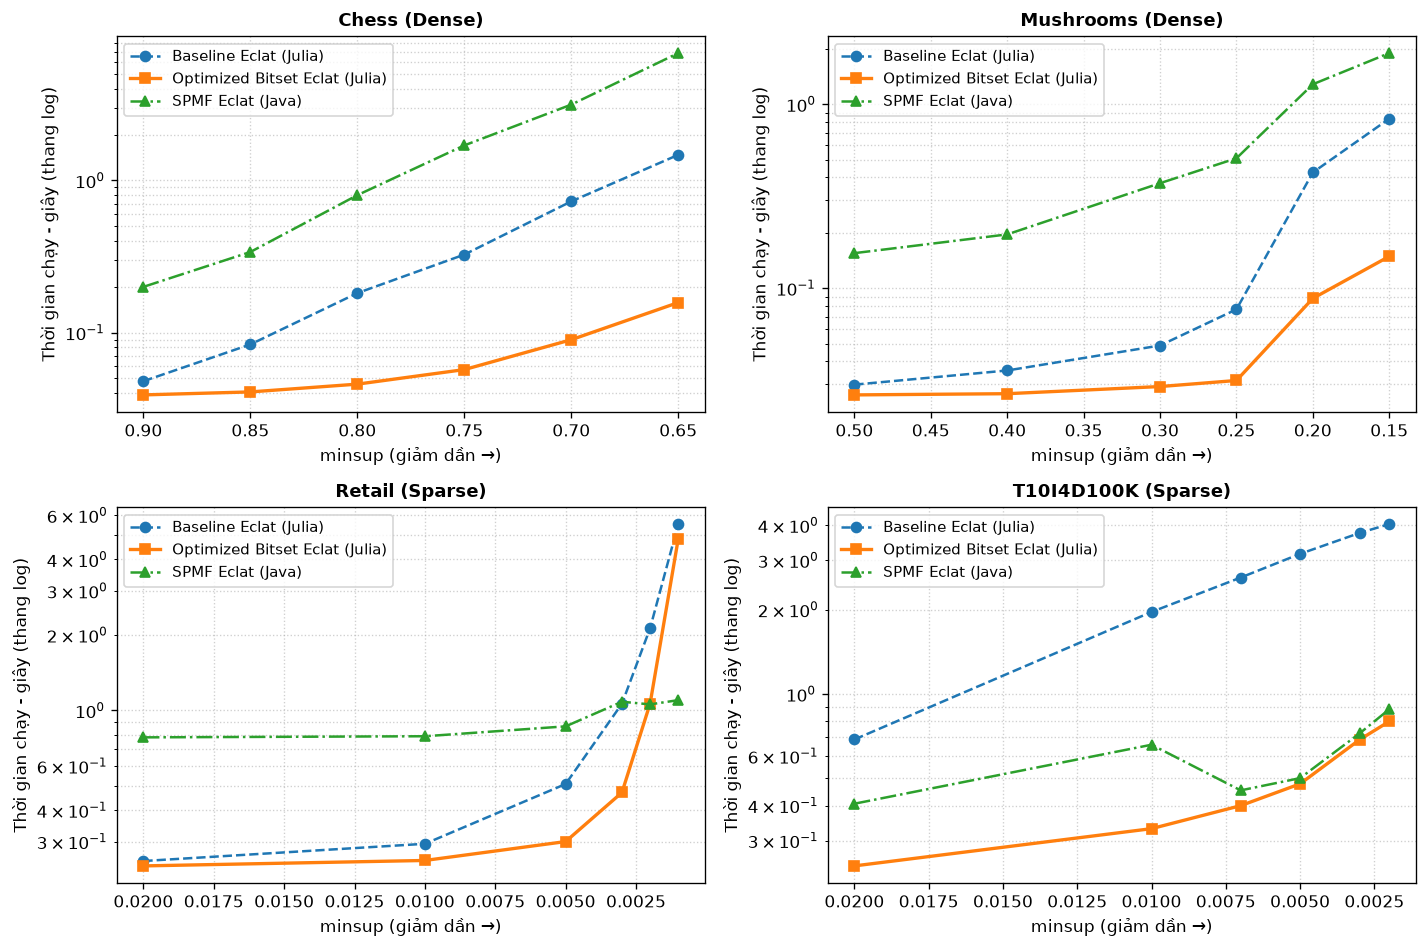

In [2]:
datasets = ["chess.txt", "mushrooms.txt", "retail.txt", "T10I4D100K.txt"]
titles   = ["Chess (Dense)", "Mushrooms (Dense)", "Retail (Sparse)", "T10I4D100K (Sparse)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, ds, title in zip(axes, datasets, titles):
    sub_base = df_main[(df_main["dataset"] == ds) & (df_main["implementation"] == "baseline")]
    sub_opt  = df_main[(df_main["dataset"] == ds) & (df_main["implementation"] == "optimized")]

    ax.plot(sub_base["minsup"], sub_base["total_seconds"], marker="o", linestyle="--", label="Baseline Eclat (Julia)")
    ax.plot(sub_opt["minsup"],  sub_opt["total_seconds"],  marker="s", linewidth=2,    label="Optimized Bitset Eclat (Julia)")
    ax.plot(sub_opt["minsup"],  sub_opt["spmf_seconds"],   marker="^", linestyle="-.", label="SPMF Eclat (Java)")

    ax.invert_xaxis()  # Hiển thị minsup giảm dần từ trái sang phải
    ax.set_yscale("log")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("minsup (giảm dần →)")
    ax.set_ylabel("Thời gian chạy - giây (thang log)")
    ax.grid(True, which="both", linestyle=":", alpha=0.6)
    ax.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "exp2_runtime_vs_minsup.png"), bbox_inches="tight")
plt.show()

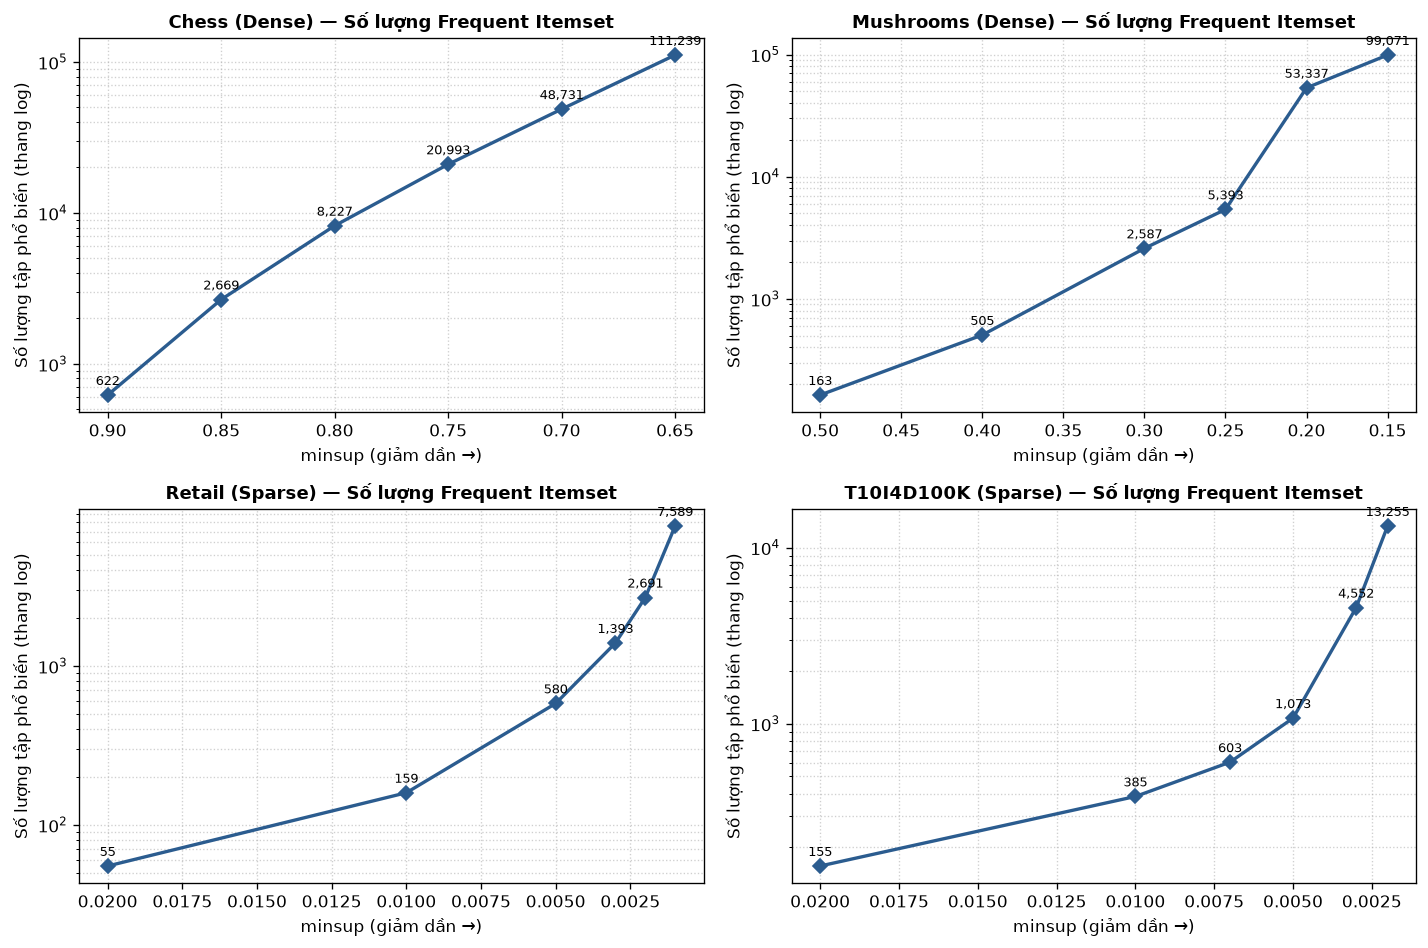

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, ds, title in zip(axes, datasets, titles):
    sub_opt = df_main[(df_main["dataset"] == ds) & (df_main["implementation"] == "optimized")]

    ax.plot(sub_opt["minsup"], sub_opt["n_itemsets"], marker="D", color="#2b5c8f", linewidth=2)
    for x, y in zip(sub_opt["minsup"], sub_opt["n_itemsets"]):
        ax.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)

    ax.invert_xaxis()
    ax.set_yscale("log")
    ax.set_title(f"{title} — Số lượng Frequent Itemset", fontweight="bold")
    ax.set_xlabel("minsup (giảm dần →)")
    ax.set_ylabel("Số lượng tập phổ biến (thang log)")
    ax.grid(True, which="both", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "exp3_itemsets_vs_minsup.png"), bbox_inches="tight")
plt.show()

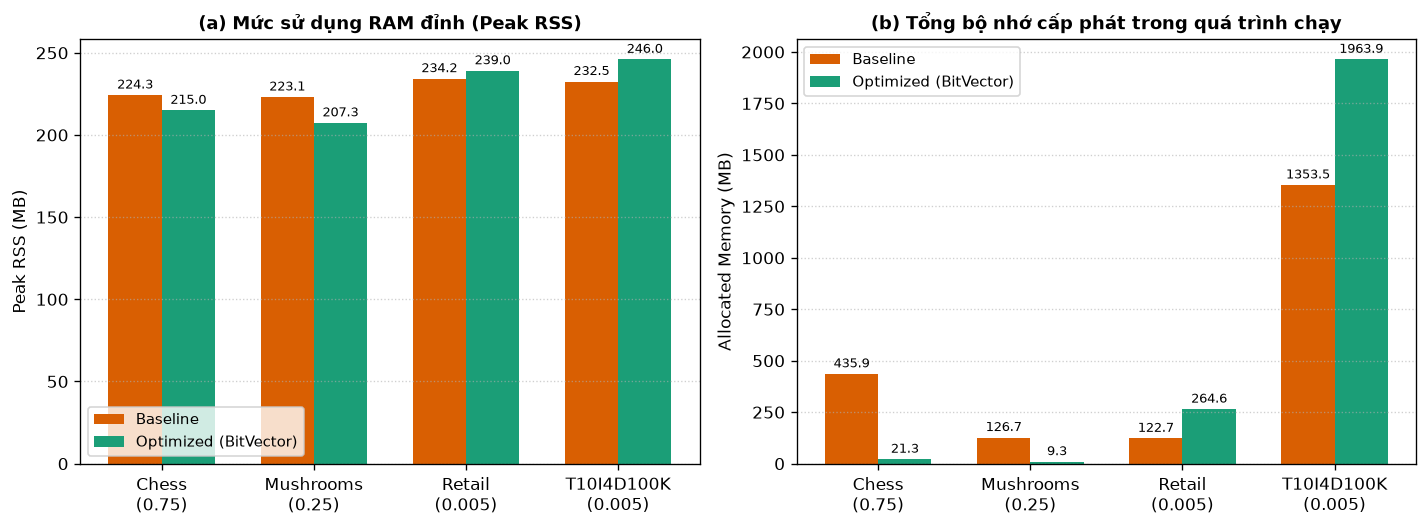

In [4]:
# Lọc dữ liệu alloc_mb tại đúng các mốc minsup trung bình trong exp4_memory.csv
med_merge = pd.merge(df_mem, df_main, on=["implementation", "dataset", "minsup"])

ds_labels = ["Chess\n(0.75)", "Mushrooms\n(0.25)", "Retail\n(0.005)", "T10I4D100K\n(0.005)"]
x = np.arange(len(datasets))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 4a: Peak RSS (MB)
rss_base = [med_merge[(med_merge["dataset"] == d) & (med_merge["implementation"] == "baseline")]["peak_rss_mb"].values[0] for d in datasets]
rss_opt  = [med_merge[(med_merge["dataset"] == d) & (med_merge["implementation"] == "optimized")]["peak_rss_mb"].values[0] for d in datasets]

b1 = ax1.bar(x - width/2, rss_base, width, label="Baseline", color="#d95f02")
b2 = ax1.bar(x + width/2, rss_opt,  width, label="Optimized (BitVector)", color="#1b9e77")
ax1.set_xticks(x)
ax1.set_xticklabels(ds_labels)
ax1.set_ylabel("Peak RSS (MB)")
ax1.set_title("(a) Mức sử dụng RAM đỉnh (Peak RSS)", fontweight="bold")
ax1.grid(axis="y", linestyle=":", alpha=0.6)
ax1.legend()
ax1.bar_label(b1, fmt="%.1f", fontsize=8, padding=2)
ax1.bar_label(b2, fmt="%.1f", fontsize=8, padding=2)

# Biểu đồ 4b: Tổng bộ nhớ cấp phát (Allocated MB)
alloc_base = [med_merge[(med_merge["dataset"] == d) & (med_merge["implementation"] == "baseline")]["alloc_mb"].values[0] for d in datasets]
alloc_opt  = [med_merge[(med_merge["dataset"] == d) & (med_merge["implementation"] == "optimized")]["alloc_mb"].values[0] for d in datasets]

b3 = ax2.bar(x - width/2, alloc_base, width, label="Baseline", color="#d95f02")
b4 = ax2.bar(x + width/2, alloc_opt,  width, label="Optimized (BitVector)", color="#1b9e77")
ax2.set_xticks(x)
ax2.set_xticklabels(ds_labels)
ax2.set_ylabel("Allocated Memory (MB)")
ax2.set_title("(b) Tổng bộ nhớ cấp phát trong quá trình chạy", fontweight="bold")
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.legend()
ax2.bar_label(b3, fmt="%.1f", fontsize=8, padding=2)
ax2.bar_label(b4, fmt="%.1f", fontsize=8, padding=2)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "exp4_memory_comparison.png"), bbox_inches="tight")
plt.show()

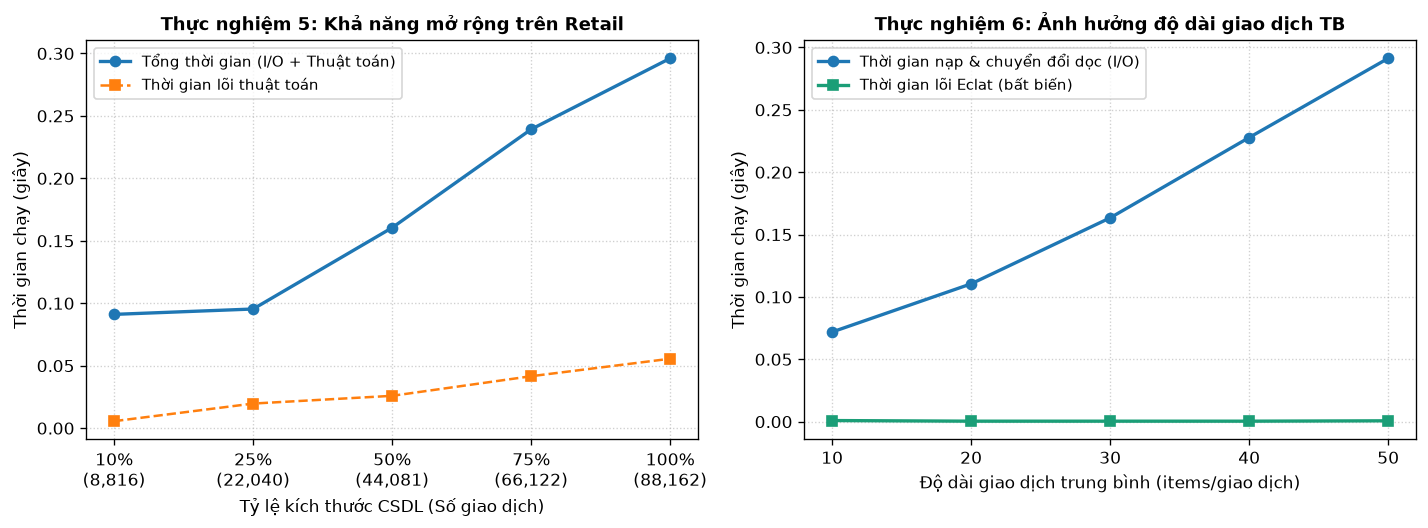

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Biểu đồ 5: Scalability trên Retail (10% -> 100%)
pct_labels = [f"{int(f*100)}%\n({n:,})" for f, n in zip(df_scale["fraction"], df_scale["num_tx"])]
ax1.plot(pct_labels, df_scale["total_seconds"], marker="o", linewidth=2, label="Tổng thời gian (I/O + Thuật toán)")
ax1.plot(pct_labels, df_scale["algo_seconds"],  marker="s", linestyle="--", label="Thời gian lõi thuật toán")
ax1.set_title("Thực nghiệm 5: Khả năng mở rộng trên Retail", fontweight="bold")
ax1.set_xlabel("Tỷ lệ kích thước CSDL (Số giao dịch)")
ax1.set_ylabel("Thời gian chạy (giây)")
ax1.grid(True, linestyle=":", alpha=0.6)
ax1.legend()

# Biểu đồ 6: Ảnh hưởng của độ dài giao dịch trung bình
ax2.plot(df_txlen["avg_tx_length"], df_txlen["load_seconds"], marker="o", linewidth=2, label="Thời gian nạp & chuyển đổi dọc (I/O)")
ax2.plot(df_txlen["avg_tx_length"], df_txlen["algo_seconds"], marker="s", linewidth=2, color="#1b9e77", label="Thời gian lõi Eclat (bất biến)")
ax2.set_title("Thực nghiệm 6: Ảnh hưởng độ dài giao dịch TB", fontweight="bold")
ax2.set_xlabel("Độ dài giao dịch trung bình (items/giao dịch)")
ax2.set_ylabel("Thời gian chạy (giây)")
ax2.set_xticks(df_txlen["avg_tx_length"])
ax2.grid(True, linestyle=":", alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "exp5_6_scalability_and_txlen.png"), bbox_inches="tight")
plt.show()